# Warm start share of the slowest calls — tertiary datasets

Port of `notebooks/02_warm_share_of_slowest.ipynb` to BEF, SPM, NSD and HUA: for each series, of
the **X% slowest calls**, what share were actually **warm** rather than cold?

| Key | Platform | Latency (ms) | Warm predicate | Series |
|---|---|---|---|---|
| **SPM** | AWS Lambda (2020) | `client_elapsed_time*1000 - elapsed_time` | `is_cold = FALSE` | Lambda20$^{\alpha}$ |
| **BEF** | multi-provider (2020) | `DLat * 1000` | `CNew = 'Reused'` | Lambda20$^{\beta}$, GCF20, Azure20, IBM20 |
| **NSD** | Google Cloud Functions (2023) | `google_time - (function_stop - function_start)*1000` | `isCold = 'False'` | GCF23 |
| **HUA** | Huawei Cloud Functions (2025) | `(totalCost_frontend - runtimeCost)*1000` | first request per `podID` is cold | Huawei25 |

HUA is not queried here — its trace is 944M rows and needs a large-memory machine. Run
`joosen_et_al/warm_share_of_slowest_huawei.ipynb` there first; this notebook reads the CSVs it
writes to `../data/tertiary_aggregations/`.

Latencies are normalised to ms: BEF's `DLat` is seconds, and SPM and NSD each mix units inside
one subtraction. Where two cold encodings exist, BEF uses `CNew` and NSD uses `isCold`.

In [1]:
from __future__ import annotations

from pathlib import Path

import duckdb
import matplotlib
import numpy as np
import pandas as pd
import seaborn as sns
from sqlalchemy import create_engine

matplotlib.use("Agg")
%matplotlib inline
import matplotlib.pyplot as plt

# Paths are relative to tertiary-repos/, where this notebook lives.
SPM_DB = Path("mahmoudi_et_al/experiments/results/results.duckdb")
SPM_TABLE = "results"

BEF_DB = Path("kuhlenkamp_et_al/full_data.duckdb")
BEF_TABLE = "full_data_enriched"

NSD_MYSQL_URL = "mysql+pymysql://root:@localhost/benchmark"
NSD_TABLE = "data"

AGG_DIR = Path("../data/tertiary_aggregations")
HUA_CURVE_CSV = AGG_DIR / "hua_warm_share_of_slowest_curve.csv"
HUA_TABLE_CSV = AGG_DIR / "hua_warm_share_of_slowest.csv"

FIG_DIR = Path("../figures/tertiary")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Platform drives colour, dataset drives line style, as in overall_analysis.ipynb.
SERIES = [
    ("SPM:aws",   "SPM", "lambda", r"Lambda20$^{\alpha}$"),
    ("BEF:aws",   "BEF", "lambda", r"Lambda20$^{\beta}$"),
    ("BEF:gcf",   "BEF", "gcf",    "GCF20"),
    ("BEF:azure", "BEF", "azure",  "Azure20"),
    ("BEF:ibm",   "BEF", "ibm",    "IBM20"),
    ("NSD:gcf",   "NSD", "gcf",    "GCF23"),
    ("HUA:huawei", "HUA", "huawei", "Huawei25"),
]
SERIES_ORDER = [s[0] for s in SERIES]
SERIES_META = {k: {"dataset": d, "platform": p, "label": lab} for k, d, p, lab in SERIES}

LINE_STYLES = {"SPM": "--", "NSD": ":", "BEF": "-", "HUA": "-."}
PLATFORM_COLORS = {
    "lambda": "#1f77b4",
    "gcf": "#2ca02c",
    "azure": "#ff7f0e",
    "ibm": "#9467bd",
    "huawei": "#d62728",
}

print(f"duckdb {duckdb.__version__}  pandas {pd.__version__}  numpy {np.__version__}")
for p in (SPM_DB, BEF_DB, HUA_CURVE_CSV, HUA_TABLE_CSV):
    print(f"  {'OK ' if p.exists() else 'MISSING'} {p}")

duckdb 1.5.6  pandas 2.3.3  numpy 2.4.6
  OK  mahmoudi_et_al/experiments/results/results.duckdb
  OK  kuhlenkamp_et_al/full_data.duckdb
  OK  ../data/tertiary_aggregations/hua_warm_share_of_slowest_curve.csv
  OK  ../data/tertiary_aggregations/hua_warm_share_of_slowest.csv


In [2]:
# Same grids and truncation floor as the source notebook.
PERCENTILES = np.linspace(0.80, 1.00, 10000)
TABLE_PERCENTILES = np.concatenate([
    np.array([0.80, 0.85, 0.90, 0.95]),
    np.linspace(0.97, 1.00, 61),
])
MIN_N_FOR_CURVE = 30


def warm_share_curve(latency, is_warm, percentiles):
    """% of calls at or above each percentile threshold that are warm, and how many that is.

    Sorts once and reads suffix sums off the sorted order instead of rescanning the array per
    percentile, which does not scale to HUA. Exact -- see the equivalence check below.
    """
    latency = np.asarray(latency, dtype=float)
    is_warm = np.asarray(is_warm, dtype=bool)
    percentiles = np.asarray(percentiles, dtype=float)
    n_total = latency.size
    if n_total == 0:
        nan = np.full(percentiles.size, np.nan)
        return nan, np.zeros(percentiles.size, dtype=np.int64), nan

    order = np.argsort(latency, kind="stable")
    lat_sorted = latency[order]
    warm_sorted = is_warm[order]

    suffix_warm = np.empty(n_total + 1, dtype=np.int64)
    suffix_warm[:n_total] = np.cumsum(warm_sorted[::-1])[::-1]
    suffix_warm[n_total] = 0

    # 'linear' matches pandas' Series.quantile default.
    thresholds = np.quantile(lat_sorted, percentiles, method="linear")
    idx = np.searchsorted(lat_sorted, thresholds, side="left")
    n = (n_total - idx).astype(np.int64)
    share = np.where(n > 0, suffix_warm[idx] / np.maximum(n, 1) * 100.0, np.nan)
    return share, n, thresholds


def _source_implementation(latency, is_warm, percentiles):
    """The source notebook's loop, kept for the equivalence check."""
    s = pd.Series(latency)
    thresholds = s.quantile(percentiles).to_numpy()
    shares, ns = [], []
    for thr in thresholds:
        mask = latency >= thr
        n = int(mask.sum())
        shares.append(float(is_warm[mask].mean() * 100.0) if n else np.nan)
        ns.append(n)
    return np.array(shares), np.array(ns, dtype=np.int64)


def test_matches_source_implementation(latency, is_warm, label):
    got_s, got_n, _ = warm_share_curve(latency, is_warm, TABLE_PERCENTILES)
    exp_s, exp_n = _source_implementation(latency, is_warm, TABLE_PERCENTILES)
    assert np.array_equal(got_n, exp_n), f"{label}: n mismatch"
    assert np.allclose(got_s, exp_s, equal_nan=True), f"{label}: share mismatch"
    print(f"  equivalence vs source implementation on {label}: OK "
          f"({len(TABLE_PERCENTILES)} percentiles, n={latency.size:,})")


print("metric helpers defined")

metric helpers defined


In [3]:
# One (latency_ms, is_warm) pair per series.
calls: dict[str, tuple[np.ndarray, np.ndarray]] = {}


def _report(key, lat, warm, dropped, filt):
    calls[key] = (lat, warm)
    print(f"{key:12s} n={lat.size:>10,}  dropped({filt})={dropped:>9,}  "
          f"cold={100.0 * (~warm).mean():>8.4f}%  median={np.median(lat):>10.3f} ms")


# SPM -- client_elapsed_time is seconds, elapsed_time is milliseconds.
con = duckdb.connect(str(SPM_DB), read_only=True)
spm = con.execute(f"""
    SELECT client_elapsed_time, elapsed_time, is_cold
    FROM {SPM_TABLE}
    WHERE client_elapsed_time IS NOT NULL
      AND elapsed_time IS NOT NULL
      AND is_cold IS NOT NULL
""").df()
con.close()

lat = pd.to_numeric(spm["client_elapsed_time"], errors="coerce") * 1000.0 \
    - pd.to_numeric(spm["elapsed_time"], errors="coerce")
warm = ~spm["is_cold"].astype(bool)
ok = lat.notna() & (lat >= 0)
_report("SPM:aws", lat[ok].to_numpy(), warm[ok].to_numpy(), int((~ok).sum()), ">= 0")


# BEF -- DLat is seconds. Drops 344 azure rows with a NULL CNew.
con = duckdb.connect(str(BEF_DB), read_only=True)
bef = con.execute(f"""
    SELECT Provider AS provider, DLat * 1000.0 AS lat_ms, CNew
    FROM {BEF_TABLE}
    WHERE RSuccessed = TRUE
      AND DLat IS NOT NULL
      AND CNew IS NOT NULL
      AND Provider IS NOT NULL
""").df()
con.close()

for prov, key in [("aws", "BEF:aws"), ("gcf", "BEF:gcf"), ("azure", "BEF:azure"), ("ibm", "BEF:ibm")]:
    sub = bef[bef["provider"] == prov]
    lat = pd.to_numeric(sub["lat_ms"], errors="coerce")
    warm = sub["CNew"].astype(str).str.strip().eq("Reused")
    ok = lat.notna() & (lat > 0)  # DLat is a direct latency, so keep the source's `> 0`
    _report(key, lat[ok].to_numpy(), warm[ok].to_numpy(), int((~ok).sum()), "> 0")


# NSD -- google_time is ms, function_start/stop are epoch seconds.
engine = create_engine(NSD_MYSQL_URL)
nsd = pd.read_sql(
    f"""SELECT google_time, function_start, function_stop, isCold
        FROM {NSD_TABLE}
        WHERE google_time IS NOT NULL
          AND function_start IS NOT NULL
          AND function_stop IS NOT NULL
          AND isCold IS NOT NULL""",
    engine,
)

google_ms = pd.to_numeric(nsd["google_time"], errors="coerce")
runtime_ms = (pd.to_numeric(nsd["function_stop"], errors="coerce")
              - pd.to_numeric(nsd["function_start"], errors="coerce")) * 1000.0

# overall_analysis.ipynb rescales google_time when this ratio drops below 0.05. Assert instead of
# rescaling silently, so a unit change is loud.
ratio = float(np.nanmedian(google_ms)) / float(np.nanmedian(runtime_ms))
assert ratio >= 0.05, f"NSD unit guard tripped: google/runtime median ratio = {ratio:.4f}"
print(f"NSD unit guard: google/runtime median ratio = {ratio:.3f} (>= 0.05, no rescale)")

lat = google_ms - runtime_ms
warm = nsd["isCold"].astype(str).str.strip().str.lower().eq("false")
ok = lat.notna() & (lat >= 0)
_report("NSD:gcf", lat[ok].to_numpy(), warm[ok].to_numpy(), int((~ok).sum()), ">= 0")

SPM:aws      n= 1,486,404  dropped(>= 0)=        0  cold=  0.1302%  median=    92.439 ms
BEF:aws      n=    95,871  dropped(> 0)=      471  cold=  1.6314%  median=    29.000 ms
BEF:gcf      n=    90,509  dropped(> 0)=        0  cold=  1.1966%  median=    83.000 ms
BEF:azure    n=     3,196  dropped(> 0)=        0  cold= 17.1464%  median= 17832.500 ms
BEF:ibm      n=    98,329  dropped(> 0)=        0  cold=  3.5981%  median=  3510.000 ms


NSD unit guard: google/runtime median ratio = 1.967 (>= 0.05, no rescale)


NSD:gcf      n= 2,073,472  dropped(>= 0)=  138,017  cold= 52.6915%  median=  1050.569 ms


In [4]:
# Check the fast metric against the source loop, on the two smallest series.
test_matches_source_implementation(*calls["BEF:azure"], "BEF:azure")
test_matches_source_implementation(*calls["BEF:gcf"], "BEF:gcf")

  equivalence vs source implementation on BEF:azure: OK (65 percentiles, n=3,196)
  equivalence vs source implementation on BEF:gcf: OK (65 percentiles, n=90,509)


In [5]:
rows_curve, rows_table = [], []
baseline_cold_pct: dict[str, float] = {}

for key, (lat, warm) in calls.items():
    meta = SERIES_META[key]
    baseline_cold_pct[key] = float((~warm).mean() * 100.0)

    share_c, n_c, thr_c = warm_share_curve(lat, warm, PERCENTILES)
    rows_curve.append(pd.DataFrame({
        "key": key, "dataset": meta["dataset"], "platform": meta["platform"], "label": meta["label"],
        "percentile": PERCENTILES * 100.0, "pct_warm": share_c, "n": n_c, "threshold_ms": thr_c,
        "baseline_cold_pct": baseline_cold_pct[key],
    }))

    share_t, n_t, thr_t = warm_share_curve(lat, warm, TABLE_PERCENTILES)
    rows_table.append(pd.DataFrame({
        "key": key, "dataset": meta["dataset"], "platform": meta["platform"], "label": meta["label"],
        "percentile": np.round(TABLE_PERCENTILES * 100.0, 2),
        "top_pct": np.round(100.0 - TABLE_PERCENTILES * 100.0, 2),
        "slowest_n": n_t, "pct_warm": share_t, "threshold_ms": thr_t,
        "baseline_cold_pct": baseline_cold_pct[key],
    }))

# HUA arrives precomputed (see joosen_et_al/warm_share_of_slowest_huawei.ipynb).
if HUA_CURVE_CSV.exists() and HUA_TABLE_CSV.exists():
    hua_c = pd.read_csv(HUA_CURVE_CSV)
    hua_t = pd.read_csv(HUA_TABLE_CSV)
    for df in (hua_c, hua_t):
        df["key"] = "HUA:huawei"
        df["label"] = SERIES_META["HUA:huawei"]["label"]
    baseline_cold_pct["HUA:huawei"] = float(hua_c["baseline_cold_pct"].iloc[0])
    rows_curve.append(hua_c[["key", "dataset", "platform", "label", "percentile",
                             "pct_warm", "n", "threshold_ms", "baseline_cold_pct"]])
    rows_table.append(hua_t[["key", "dataset", "platform", "label", "percentile", "top_pct",
                             "slowest_n", "pct_warm", "threshold_ms", "baseline_cold_pct"]])
    print(f"HUA:huawei   loaded from {HUA_CURVE_CSV.name} "
          f"(baseline cold {baseline_cold_pct['HUA:huawei']:.4f}%)")
else:
    print(f"HUA:huawei   MISSING -- run joosen_et_al/warm_share_of_slowest_huawei.ipynb on a large-memory machine")

df_curve = pd.concat(rows_curve, ignore_index=True).dropna(subset=["pct_warm"])
df_table = pd.concat(rows_table, ignore_index=True)

for df in (df_curve, df_table):
    df["pct_cold"] = 100.0 - df["pct_warm"]
    df["cold_enrichment"] = df["pct_cold"] / df["baseline_cold_pct"]

# Only the plotted curve is truncated; the table keeps every row, with its N.
df_curve_plot = df_curve[df_curve["n"] >= MIN_N_FOR_CURVE].copy()

print(f"\nMIN_N_FOR_CURVE = {MIN_N_FOR_CURVE}: where each curve stops")
for key in SERIES_ORDER:
    sub = df_curve_plot[df_curve_plot["key"] == key]
    if sub.empty:
        print(f"  {key:12s} -- no points")
        continue
    full = df_curve[df_curve["key"] == key]
    # n is the count backing each point, so its max is the count at p80.
    print(f"  {key:12s} n@p80={int(full['n'].max()):>10,}  "
          f"curve ends at p{sub['percentile'].max():.4f}")

HUA:huawei   loaded from hua_warm_share_of_slowest_curve.csv (baseline cold 0.0210%)

MIN_N_FOR_CURVE = 30: where each curve stops
  SPM:aws      n@p80=   297,281  curve ends at p99.9980
  BEF:aws      n@p80=    20,864  curve ends at p99.9680
  BEF:gcf      n@p80=    18,150  curve ends at p99.9660
  BEF:azure    n@p80=       640  curve ends at p99.0919
  BEF:ibm      n@p80=    19,678  curve ends at p99.9700
  NSD:gcf      n@p80=   414,695  curve ends at p99.9980
  HUA:huawei   n@p80=158,672,462  curve ends at p99.9980


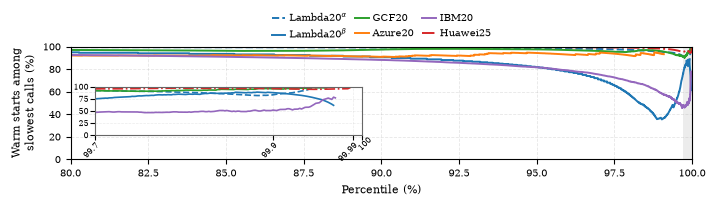

wrote ../figures/tertiary/warm-share-of-slowest.pdf


In [6]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ACM Middleware 2-column format, matching the source notebook.
plt.rcParams.update({
    'font.size': 8,
    'axes.titlesize': 8,
    'axes.labelsize': 8,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'legend.fontsize': 7,
    'font.family': 'serif',
})

# NSD's warm-share is pinned near zero across the whole range, so the curve carries no tail
# information. It stays in the table and the CSV.
EXCLUDED_FROM_PLOT: set[str] = {"NSD:gcf"}


def series_in(df, excluded):
    present = set(df["key"])
    return [k for k in SERIES_ORDER if k not in excluded and k in present]


def style(key):
    meta = SERIES_META[key]
    return dict(color=PLATFORM_COLORS[meta["platform"]], linestyle=LINE_STYLES[meta["dataset"]])


keys = series_in(df_curve_plot, EXCLUDED_FROM_PLOT)

fig, ax = plt.subplots(figsize=(7.0, 2.35))
for key in keys:
    d = df_curve_plot[df_curve_plot["key"] == key].sort_values("percentile")
    ax.plot(d["percentile"], d["pct_warm"], linewidth=1.4,
            label=SERIES_META[key]["label"], **style(key))

ax.set_xlabel("Percentile (%)")
ax.set_ylabel("Warm starts among\nslowest calls (%)")
ax.set_xlim(80, 100)
ax.set_ylim(0, 100)
ax.grid(True, linestyle="--", alpha=0.30, linewidth=0.6)

ncol = min(4, max(1, int(np.ceil(len(keys) / 2))))
ax.legend(title=None, loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=ncol, frameon=False,
          handlelength=1.4, columnspacing=0.9, handletextpad=0.4, borderaxespad=0.0)

fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.82), pad=0.2)

# A shaded band rather than mark_inset: these curves move across the full y-range, so connector
# lines would cut across real data.
ax.axvspan(99.7, 100, color="0.4", alpha=0.12, linewidth=0)

axins = inset_axes(ax, width="43%", height="43%", loc="lower left", borderpad=2.5)
for key in keys:
    d = df_curve_plot[df_curve_plot["key"] == key].sort_values("percentile")
    axins.plot(d["percentile"], d["pct_warm"], linewidth=1.2, **style(key))

axins.set_xlim(99.7, 100)
axins.set_ylim(0, 100)
axins.grid(True, linestyle="--", alpha=0.25, linewidth=0.5)
axins.set_xticks([99.7, 99.9, 99.99, 100])
axins.set_xticklabels(["99.7", "99.9", "99.99", "100"], rotation=45, ha="right",
                      rotation_mode="anchor")
for lbl in axins.get_xticklabels():
    if lbl.get_text() == "100":
        lbl.set_ha("center")
axins.set_yticks([0, 25, 50, 75, 100])
axins.tick_params(axis='both', labelsize=6, pad=1)
axins.set_xlabel("")
axins.set_ylabel("")
for spine in axins.spines.values():
    spine.set_edgecolor("0.4")
    spine.set_linewidth(0.8)

fig.savefig(FIG_DIR / "warm-share-of-slowest.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"wrote {FIG_DIR / 'warm-share-of-slowest.pdf'}")

In [7]:
print("\n" + "=" * 92)
print("Warm-start share among the slowest calls, per percentile — tertiary datasets")
print("(p80, p85, p90, p95, then p97.00..p100.00 in 0.05-point steps)")
print("=" * 92)

for key in SERIES_ORDER:
    sub = df_table[df_table["key"] == key]
    if sub.empty:
        continue
    meta = SERIES_META[key]
    print(f"\n--- {key}  ({meta['dataset']} / {meta['platform']})  "
          f"baseline cold {baseline_cold_pct[key]:.4f}% ---")
    cols = ["percentile", "top_pct", "slowest_n", "pct_warm", "pct_cold",
            "threshold_ms", "cold_enrichment"]
    print(sub[cols].round(3).to_string(index=False))

print("\n" + "=" * 92 + "\n")


Warm-start share among the slowest calls, per percentile — tertiary datasets
(p80, p85, p90, p95, then p97.00..p100.00 in 0.05-point steps)

--- SPM:aws  (SPM / lambda)  baseline cold 0.1302% ---
 percentile  top_pct  slowest_n  pct_warm  pct_cold  threshold_ms  cold_enrichment
      80.00    20.00     297281    99.637     0.363       101.857            2.784
      85.00    15.00     222961    99.535     0.465       107.645            3.571
      90.00    10.00     148641    99.328     0.672       120.504            5.160
      95.00     5.00      74321    98.712     1.288       178.217            9.886
      97.00     3.00      44593    98.022     1.978       328.909           15.186
      97.05     2.95      43849    98.000     2.000       329.109           15.356
      97.10     2.90      43106    97.968     2.032       329.326           15.603
      97.15     2.85      42363    97.932     2.068       329.538           15.876
      97.20     2.80      41620    97.902     2.098     

## Cold-start enrichment relative to each dataset's baseline

For each series,

```
enrichment(X%) = P(cold | among the slowest X% calls) / P(cold overall)
```

A ratio of 1 means the tail's cold/warm mix just matches that series' normal traffic; above 1
means cold starts are over-represented there.

The baselines here span three very different regimes — BEF and SPM are observational, NSD is a
designed ~50/50 cold/warm split, and HUA has no cold flag at all (first request per pod is taken
as cold). The shape of each curve against its own baseline is meaningful; the *levels* across
series are not directly comparable.

Azure20 is a counterexample to the source notebook's "never drops below 1" claim: its ratio sits
between 0.30 and 0.53 throughout, though on only 3,196 calls, so its curve stops at p99.09.

The log plot is the one to read for the cross-dataset comparison.

In [8]:
df_enrich_plot = df_curve_plot.copy()

print("Baseline cold-start rate and peak enrichment per series")
for key in SERIES_ORDER:
    d = df_enrich_plot[df_enrich_plot["key"] == key]
    if d.empty:
        continue
    print(f"  {key:12s} baseline={baseline_cold_pct[key]:>8.4f}%   "
          f"enrichment: min={d['cold_enrichment'].min():>8.3f}  "
          f"max={d['cold_enrichment'].max():>10.3f}  "
          f"at p{d.loc[d['cold_enrichment'].idxmax(), 'percentile']:.3f}")

Baseline cold-start rate and peak enrichment per series
  SPM:aws      baseline=  0.1302%   enrichment: min=   0.000  max=   141.982  at p99.884
  BEF:aws      baseline=  1.6314%   enrichment: min=   3.076  max=    39.594  at p99.028
  BEF:gcf      baseline=  1.1966%   enrichment: min=   0.000  max=     8.100  at p99.750
  BEF:azure    baseline= 17.1464%   enrichment: min=   0.299  max=     0.534  at p90.423
  BEF:ibm      baseline=  3.5981%   enrichment: min=   2.052  max=    15.118  at p99.688
  NSD:gcf      baseline= 52.6915%   enrichment: min=   1.889  max=     1.898  at p99.992
  HUA:huawei   baseline=  0.0210%   enrichment: min=   1.138  max=   270.166  at p99.944


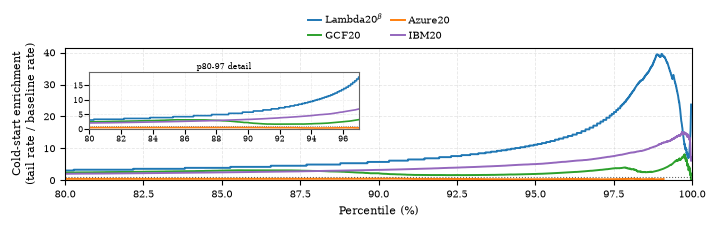

wrote ../figures/tertiary/cold-enrichment-linear.pdf


In [9]:
# HUA (270x) and SPM (142x) would flatten everything else on a linear axis -- max elsewhere is
# 39.6x. They come back on the log plot. What is left is BEF's four providers, whose baselines
# are all within one order of magnitude.
EXCLUDED_LINEAR: set[str] = {"NSD:gcf", "SPM:aws", "HUA:huawei"}

keys = series_in(df_enrich_plot, EXCLUDED_LINEAR)

fig, ax = plt.subplots(figsize=(7.0, 2.6))
for key in keys:
    d = df_enrich_plot[df_enrich_plot["key"] == key].sort_values("percentile")
    ax.plot(d["percentile"], d["cold_enrichment"], linewidth=1.4,
            label=SERIES_META[key]["label"], **style(key))

ax.axhline(1.0, color="black", linewidth=0.8, linestyle=":", alpha=0.6)
ax.set_xlabel("Percentile (%)")
ax.set_ylabel("Cold-start enrichment\n(tail rate / baseline rate)")
ax.set_xlim(80, 100)
y_max = df_enrich_plot[df_enrich_plot["key"].isin(keys)]["cold_enrichment"].max()
ax.set_ylim(0, y_max * 1.05)
ax.grid(True, linestyle="--", alpha=0.30, linewidth=0.6)

ncol = min(4, max(1, int(np.ceil(len(keys) / 2))))
ax.legend(title=None, loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=ncol, frameon=False,
          handlelength=1.4, columnspacing=0.9, handletextpad=0.4, borderaxespad=0.0)

fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.82), pad=0.2)

# The deep-tail spike dwarfs everything on a linear axis, so zoom below p97 instead of the tail.
axins = inset_axes(ax, width="43%", height="43%", loc="upper left", borderpad=2.5)
for key in keys:
    d = df_enrich_plot[(df_enrich_plot["key"] == key)
                       & (df_enrich_plot["percentile"] <= 97)].sort_values("percentile")
    axins.plot(d["percentile"], d["cold_enrichment"], linewidth=1.2, **style(key))
axins.axhline(1.0, color="black", linewidth=0.6, linestyle=":", alpha=0.6)
axins.set_xlim(80, 97)
y_max_inset = df_enrich_plot[(df_enrich_plot["key"].isin(keys))
                             & (df_enrich_plot["percentile"] <= 97)]["cold_enrichment"].max()
axins.set_ylim(0, y_max_inset * 1.1)
axins.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(nbins=4))
axins.grid(True, linestyle="--", alpha=0.25, linewidth=0.5)
axins.tick_params(axis="both", labelsize=6, pad=1)
axins.set_xlabel("")
axins.set_ylabel("")
axins.set_title("p80-97 detail", fontsize=6, pad=2)
for spine in axins.spines.values():
    spine.set_edgecolor("0.4")
    spine.set_linewidth(0.8)

fig.savefig(FIG_DIR / "cold-enrichment-linear.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"wrote {FIG_DIR / 'cold-enrichment-linear.pdf'}")

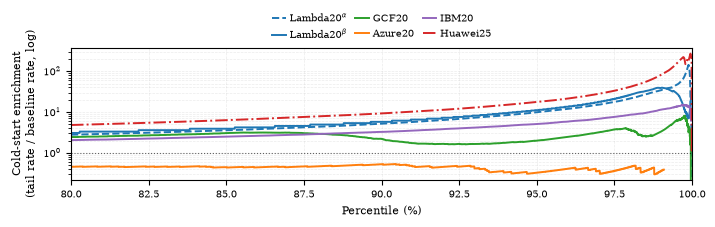

wrote ../figures/tertiary/cold-enrichment-log.pdf


In [10]:
# Log axis fits SPM's ~142x and HUA's ~270x alongside Azure20's ~0.45.
EXCLUDED_LOG: set[str] = {"NSD:gcf"}

keys = series_in(df_enrich_plot, EXCLUDED_LOG)

fig, ax = plt.subplots(figsize=(7.0, 2.6))
for key in keys:
    d = df_enrich_plot[df_enrich_plot["key"] == key].sort_values("percentile")
    ax.plot(d["percentile"], d["cold_enrichment"], linewidth=1.4,
            label=SERIES_META[key]["label"], **style(key))

ax.axhline(1.0, color="black", linewidth=0.8, linestyle=":", alpha=0.6)
ax.set_yscale("log")
ax.set_xlabel("Percentile (%)")
ax.set_ylabel("Cold-start enrichment\n(tail rate / baseline rate, log)")
ax.set_xlim(80, 100)
ax.grid(True, which="both", linestyle="--", alpha=0.25, linewidth=0.5)

ncol = min(4, max(1, int(np.ceil(len(keys) / 2))))
ax.legend(title=None, loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=ncol, frameon=False,
          handlelength=1.4, columnspacing=0.9, handletextpad=0.4, borderaxespad=0.0)

fig.tight_layout(rect=(0.0, 0.0, 1.0, 0.82), pad=0.2)
fig.savefig(FIG_DIR / "cold-enrichment-log.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"wrote {FIG_DIR / 'cold-enrichment-log.pdf'}")

In [11]:
out = AGG_DIR / "tertiary_warm_share_of_slowest.csv"
cols = ["key", "dataset", "platform", "label", "percentile", "top_pct", "slowest_n",
        "pct_warm", "pct_cold", "threshold_ms", "baseline_cold_pct", "cold_enrichment"]
df_out = df_table[cols].sort_values(
    ["key", "percentile"],
    key=lambda s: s.map({k: i for i, k in enumerate(SERIES_ORDER)}) if s.name == "key" else s,
)
df_out.to_csv(out, index=False)
print(f"wrote {out}  ({out.stat().st_size / 1024:,.1f} KiB, {len(df_out):,} rows)")

wrote ../data/tertiary_aggregations/tertiary_warm_share_of_slowest.csv  (58.5 KiB, 455 rows)
